In [1]:
import sys
sys.path.append('..')

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.data.database import EntityDatabase

from src.data.experiment_data import (
    get_entities_with_complete_data,
    get_entity_summary,
    validate_entity_completeness,
    count_entities_by_culture,
    count_entities_by_country
)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## 1. Connect to Database

In [2]:
db_path = Path('../data/entities.db')
conn = sqlite3.connect(db_path)

print(f"✓ Connected to database: {db_path}")
print(f"  Database size: {db_path.stat().st_size / 1024 / 1024:.2f} MB")

✓ Connected to database: ../data/entities.db
  Database size: 806.34 MB


In [3]:
db = EntityDatabase(db_path)

## 2. Explore Database Contents

In [4]:
# Count total entities
total_entities = pd.read_sql_query('SELECT COUNT(*) as count FROM entities', conn)['count'][0]
print(f"Total entities: {total_entities}")

# Count by entity type
by_type = pd.read_sql_query(
    'SELECT type, COUNT(*) as count FROM entities GROUP BY type',
    conn
)
print("\nEntities by type:")
print(by_type.to_string(index=False))

Total entities: 37254

Entities by type:
  type  count
person  37254


In [5]:
# Count Wikipedia texts by language
wiki_counts = pd.read_sql_query(
    'SELECT language, COUNT(DISTINCT entity_id) as count FROM wikipedia_texts GROUP BY language',
    conn
)
print("Wikipedia texts by language:")
print(wiki_counts.to_string(index=False))

Wikipedia texts by language:
language  count
      ar  35407
      en  35322
      fr  28075


In [6]:
# Count facts by property
fact_counts = pd.read_sql_query(
    '''SELECT f.property, COUNT(DISTINCT f.entity_id) as count
       FROM facts f
       GROUP BY f.property''',
    conn
)
print("Facts by property:")
print(fact_counts.to_string(index=False))

Facts by property:
   property  count
  birthDate  37254
 birthPlace  37254
  deathDate  11258
     gender  37252
nationality  37254
 occupation  37254


## 3. Filter Entities with Complete Data

In [7]:
# Get entities with complete data
languages = ['en', 'fr', 'ar']
entity_type = 'person'
required_facts = ['birthPlace', 'nationality', 'birthDate']

print(f"Filtering entities with:")
print(f"  Languages: {languages}")
print(f"  Entity type: {entity_type}")
print(f"  Required facts: {required_facts}")
print()

complete_entities = get_entities_with_complete_data(
    db,
    languages=languages,
    entity_type=entity_type,
    required_facts=required_facts
)

print(f"\n✓ Found {len(complete_entities)} entities with complete data")

# ============================================================================
# ADDITIONAL VALIDATION: Verify Wikipedia texts exist for ALL languages
# ============================================================================
print("\n" + "="*60)
print("VALIDATING WIKIPEDIA TEXTS FOR ALL LANGUAGES")
print("="*60)

validated_entities = []
missing_wiki_count = {'en': 0, 'fr': 0, 'ar': 0}

for entity in complete_entities:
    entity_id = entity['id']
    wiki_texts = db.get_wikipedia_texts(entity_id)

    has_all_wikis = True
    for lang in languages:
        # Check if language exists AND has non-empty summary
        if lang not in wiki_texts:
            missing_wiki_count[lang] += 1
            has_all_wikis = False
        elif not wiki_texts[lang].get('summary') or len(wiki_texts[lang]['summary'].strip()) == 0:
            missing_wiki_count[lang] += 1
            has_all_wikis = False

    if has_all_wikis:
        validated_entities.append(entity)

print(f"\nMissing Wikipedia texts:")
for lang, count in missing_wiki_count.items():
    print(f"  {lang}: {count} entities missing")

print(f"\n✓ Validated entities with ALL Wikipedia texts: {len(validated_entities)}")
print(f"  Removed: {len(complete_entities) - len(validated_entities)} entities")

# Use validated entities
complete_entities = validated_entities

Filtering entities with:
  Languages: ['en', 'fr', 'ar']
  Entity type: person
  Required facts: ['birthPlace', 'nationality', 'birthDate']


✓ Found 26098 entities with complete data

VALIDATING WIKIPEDIA TEXTS FOR ALL LANGUAGES

Missing Wikipedia texts:
  en: 0 entities missing
  fr: 3 entities missing
  ar: 24 entities missing

✓ Validated entities with ALL Wikipedia texts: 26071
  Removed: 27 entities


In [8]:
# ============================================================================
# ADDITIONAL FILTER: Complete fact labels in ALL languages FOR ALL VALUES
# ============================================================================
print("\n" + "="*60)
print("FILTERING FOR COMPLETE FACT LABELS (ALL VALUES)")
print("="*60)

filtered_entities = []
missing_fact_labels = {
    'birthPlace': {'en': 0, 'fr': 0, 'ar': 0},
    'nationality': {'en': 0, 'fr': 0, 'ar': 0}
}
entities_with_multiple_values = {'birthPlace': 0, 'nationality': 0}

for entity in complete_entities:
    entity_id = entity['id']
    facts = db.get_entity_facts(entity_id)

    # Group facts by property to handle multiple values
    from collections import defaultdict
    facts_by_property = defaultdict(list)
    for fact in facts:
        facts_by_property[fact['property']].append(fact)

    # Check that ALL facts of each property have labels in all languages
    has_complete_labels = True

    for fact_property in ['birthPlace', 'nationality']:
        if fact_property not in facts_by_property:
            # Fact doesn't exist (shouldn't happen after earlier filtering)
            has_complete_labels = False
            continue

        # Track entities with multiple values for reporting
        if len(facts_by_property[fact_property]) > 1:
            entities_with_multiple_values[fact_property] += 1

        # Check EACH fact value has labels in all languages
        for fact in facts_by_property[fact_property]:
            fact_labels = fact.get('labels', {})
            for lang in languages:
                if lang not in fact_labels or not fact_labels[lang]:
                    missing_fact_labels[fact_property][lang] += 1
                    has_complete_labels = False

    if has_complete_labels:
        filtered_entities.append(entity)

print(f"\nEntities with multiple values:")
for fact_property, count in entities_with_multiple_values.items():
    print(f"  {fact_property}: {count} entities have multiple values")

print(f"\nEntities with missing fact labels (excluding due to incomplete labels on ANY value):")
for fact_property, lang_counts in missing_fact_labels.items():
    print(f"  {fact_property}:")
    for lang, count in lang_counts.items():
        print(f"    {lang}: {count} fact values missing labels")

print(f"\n✓ Entities with complete fact labels (ALL values): {len(filtered_entities)}")
print(f"  Removed: {len(complete_entities) - len(filtered_entities)} entities")
print(f"  Reason: At least one fact value was missing labels in at least one language")

# Use filtered entities
complete_entities = filtered_entities


FILTERING FOR COMPLETE FACT LABELS (ALL VALUES)

Entities with multiple values:
  birthPlace: 2 entities have multiple values
  nationality: 123 entities have multiple values

Entities with missing fact labels (excluding due to incomplete labels on ANY value):
  birthPlace:
    en: 0 fact values missing labels
    fr: 563 fact values missing labels
    ar: 2881 fact values missing labels
  nationality:
    en: 0 fact values missing labels
    fr: 0 fact values missing labels
    ar: 0 fact values missing labels

✓ Entities with complete fact labels (ALL values): 23007
  Removed: 3064 entities
  Reason: At least one fact value was missing labels in at least one language


In [9]:
# ============================================================================
# CELL: Final Validation - Count texts per language
# ============================================================================
print("\n" + "="*60)
print("FINAL VALIDATION: Wikipedia text counts")
print("="*60)

text_counts = {'en': 0, 'fr': 0, 'ar': 0}

for entity in complete_entities:
    entity_id = entity['id']
    wiki_texts = db.get_wikipedia_texts(entity_id)

    for lang in languages:
        if lang in wiki_texts and wiki_texts[lang].get('summary'):
            text_counts[lang] += 1

print(f"\nWikipedia texts per language:")
for lang, count in text_counts.items():
    match = "✓" if count == len(complete_entities) else "✗"
    print(f"  {lang}: {count} / {len(complete_entities)} {match}")

# Verify all counts match
assert all(count == len(complete_entities) for count in text_counts.values()), \
    "ERROR: Not all entities have Wikipedia texts in all languages!"

print(f"\n✓ All {len(complete_entities)} entities have Wikipedia texts in EN, FR, and AR")


FINAL VALIDATION: Wikipedia text counts

Wikipedia texts per language:
  en: 23007 / 23007 ✓
  fr: 23007 / 23007 ✓
  ar: 23007 / 23007 ✓

✓ All 23007 entities have Wikipedia texts in EN, FR, and AR


In [10]:
complete_entities[0]

{'id': 1,
 'wikidata_id': 'Q10738',
 'type': 'person',
 'culture': 'Western',
 'country': 'United States',
 'created_at': '2025-12-17 00:26:11',
 'label': 'Dwayne Johnson',
 'labels': {'ar': 'دوين جونسون',
  'en': 'Dwayne Johnson',
  'fr': 'Dwayne Johnson'}}

## 4. Inspect Sample Entities

In [11]:
# Show first 5 entities
print("Sample entities:")
for i, entity in enumerate(complete_entities[:5], 1):
    print(f"\n{i}. {entity['label']} (ID: {entity['id']})")
    print(f"   Wikidata: {entity['wikidata_id']}")
    if 'culture' in entity:
        print(f"   Culture: {entity['culture']}")
    if 'country' in entity:
        print(f"   Country: {entity['country']}")

Sample entities:

1. Dwayne Johnson (ID: 1)
   Wikidata: Q10738
   Culture: Western
   Country: United States

2. Mick Foley (ID: 2)
   Wikidata: Q10731
   Culture: Western
   Country: United States

3. Bill Clinton (ID: 3)
   Wikidata: Q1124
   Culture: Western
   Country: United States

4. Madonna (ID: 4)
   Wikidata: Q1744
   Culture: Western
   Country: United States

5. Jimmy Bennett (ID: 5)
   Wikidata: Q4349
   Culture: Western
   Country: United States


In [12]:
# Get detailed summary of first entity
first_entity_id = complete_entities[0]['id']
summary = get_entity_summary(db, first_entity_id, languages)

print(f"Detailed summary for entity {first_entity_id}:")
print(f"\nLabel: {summary['label']}")
print(f"Type: {summary['entity_type']}")
print(f"Wikidata: {summary['wikidata_id']}")

print(f"\nLabels by language:")
for lang, label in summary['labels'].items():
    print(f"  {lang}: {label}")

print(f"\nFacts:")
for fact in summary['facts']:
    # Show English label if available, otherwise show value
    if 'labels' in fact and 'en' in fact['labels']:
        label = fact['labels']['en']
    else:
        label = fact['value']
    print(f"  {fact['property']}: {label}")

print(f"\nWikipedia texts:")
for wiki in summary['wikipedia_texts']:
    text_preview = wiki['text'][:100] + '...' if len(wiki['text']) > 100 else wiki['text']
    print(f"  {wiki['language']}: {text_preview}")

Detailed summary for entity 1:

Label: Dwayne Johnson
Type: person
Wikidata: Q10738

Labels by language:
  ar: دوين جونسون
  en: Dwayne Johnson
  fr: Dwayne Johnson

Facts:
  birthDate: 1972-05-02T00:00:00Z
  birthPlace: Hayward
  gender: http://www.wikidata.org/entity/Q6581097
  nationality: United States
  occupation: Canadian football player

Wikipedia texts:
  ar: دوين دوغلاس جونسون (بالإنجليزية: Dwayne Douglas Johnson) (من مواليد 2 مايو 1972) والمعروف أيضًا باسم...
  en: Dwayne Douglas Johnson (born May 2, 1972), also known by his ring name "the Rock", is an American ac...
  fr: Dwayne Johnson ([ˈdweɪn ˈd͡ʒɑnsən]) est un acteur, producteur et catcheur (lutteur professionnel) am...


## 5. Analyze Entity Distribution

In [13]:
# Count by culture
culture_counts = count_entities_by_culture(complete_entities)

print("Entities by culture:")
for culture, count in sorted(culture_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {culture}: {count}")

Entities by culture:
  Western: 6010
  Latin American: 5150
  East Asian: 4096
  Arabic: 3714
  African: 2329
  South Asian: 1247
  Southeast Asian: 461


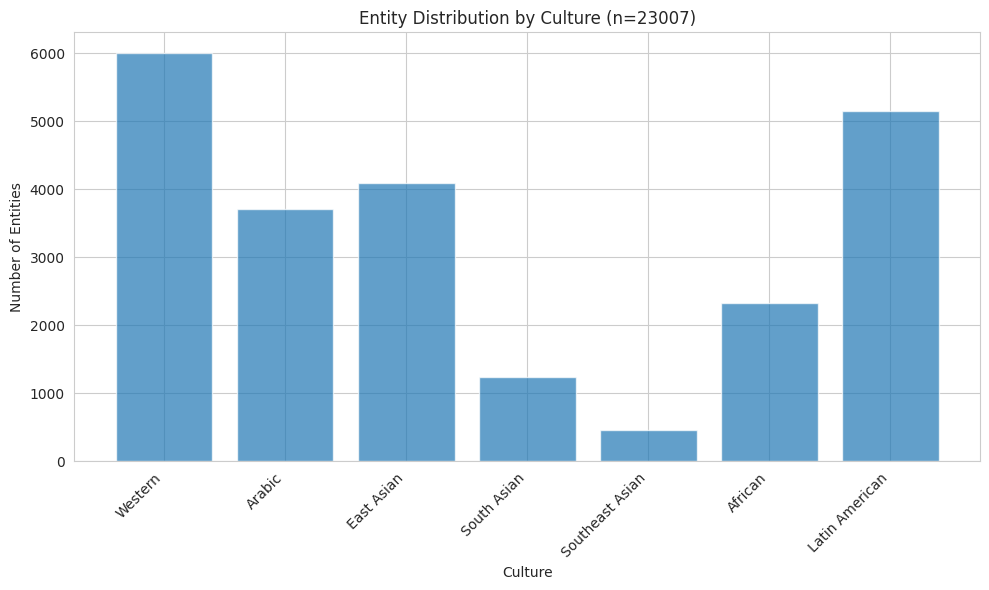

In [14]:
# Visualize culture distribution
fig, ax = plt.subplots(figsize=(10, 6))

cultures = list(culture_counts.keys())
counts = list(culture_counts.values())

ax.bar(range(len(cultures)), counts, alpha=0.7)
ax.set_xticks(range(len(cultures)))
ax.set_xticklabels(cultures, rotation=45, ha='right')
ax.set_xlabel('Culture')
ax.set_ylabel('Number of Entities')
ax.set_title(f'Entity Distribution by Culture (n={len(complete_entities)})')

plt.tight_layout()
plt.show()

In [15]:
# Count by country
country_counts = count_entities_by_country(complete_entities)

print(f"\nEntities by country (top 10):")
for country, count in sorted(country_counts.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"  {country}: {count}")


Entities by country (top 10):
  Japan: 1666
  United States: 1650
  Brazil: 1589
  Morocco: 1514
  Germany: 1487
  France: 1480
  Argentina: 1451
  United Kingdom: 1393
  Egypt: 1275
  Mexico: 1215


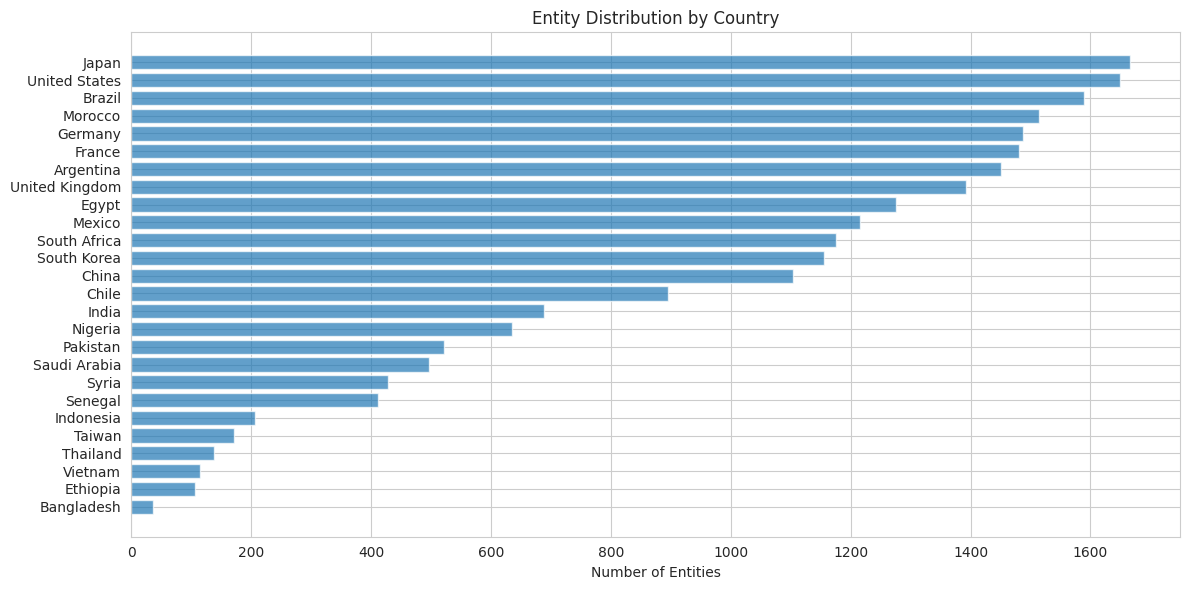

In [16]:
# Visualize top countries
fig, ax = plt.subplots(figsize=(12, 6))

top_countries = sorted(country_counts.items(), key=lambda x: x[1], reverse=True)
countries = [c[0] for c in top_countries]
counts = [c[1] for c in top_countries]

ax.barh(range(len(countries)), counts, alpha=0.7)
ax.set_yticks(range(len(countries)))
ax.set_yticklabels(countries)
ax.set_xlabel('Number of Entities')
ax.set_title('Entity Distribution by Country')
ax.invert_yaxis()

plt.tight_layout()
plt.show()

## 6. Select Final Entity Set

In [17]:
# Option 1: Use all entities with complete data
selected_entities = complete_entities

# Option 2: Select a subset (e.g., first 50 for initial experiments)
# selected_entities = complete_entities[:50]

# Option 3: Balance by culture
# min_per_culture = 10
# selected_entities = []
# for culture in culture_counts.keys():
#     culture_entities = [e for e in complete_entities if e.get('culture') == culture]
#     selected_entities.extend(culture_entities[:min_per_culture])

print(f"Selected {len(selected_entities)} entities for experiment")

Selected 23007 entities for experiment


## 6.5. Enrich Selected Entities with Metadata

In [ ]:
def decode_gender(wikidata_uri):
    """
    Decode Wikidata gender URI to human-readable value.

    Args:
        wikidata_uri: Wikidata entity URI (e.g., 'http://www.wikidata.org/entity/Q6581097')

    Returns:
        str: 'male', 'female', or None if unknown
    """
    if not wikidata_uri:
        return None

    # Extract entity ID from URI
    if 'Q6581097' in wikidata_uri:
        return 'male'
    elif 'Q6581072' in wikidata_uri:
        return 'female'
    else:
        return None

In [ ]:
# Enrich entities with metadata from database
print("Enriching entities with metadata...")
print(f"Processing {len(selected_entities)} entities...")

enriched_count = 0
for entity in selected_entities:
    entity_id = entity['id']

    # Get metadata (num_wikipedia_languages, birth_year)
    metadata = db.get_metadata(entity_id)
    entity['num_wikipedia_languages'] = metadata.get('num_wikipedia_languages', None)
    entity['birth_year'] = metadata.get('birth_year', None)

    # Get facts (gender, occupation with multilingual labels)
    facts = db.get_entity_facts(entity_id)

    # Initialize occupation fields
    entity['occupation_en'] = None
    entity['occupation_fr'] = None
    entity['occupation_ar'] = None
    entity['sex'] = None

    for fact in facts:
        if fact['property'] == 'gender':
            entity['sex'] = decode_gender(fact['value'])
        elif fact['property'] == 'occupation':
            # Get occupation labels in all languages
            labels = fact.get('labels', {})
            entity['occupation_en'] = labels.get('en')
            entity['occupation_fr'] = labels.get('fr')
            entity['occupation_ar'] = labels.get('ar')
            # Break after first occupation (only 1 stored per entity)
            break

    enriched_count += 1
    if enriched_count % 1000 == 0:
        print(f"  Processed {enriched_count}/{len(selected_entities)} entities...")

print(f"\n✓ Enriched {len(selected_entities)} entities with metadata")
print(f"  Added columns: sex, occupation_en/fr/ar, num_wikipedia_languages, birth_year")

Enriching entities with metadata...
Processing 23007 entities...
  Processed 1000/23007 entities...
  Processed 2000/23007 entities...
  Processed 3000/23007 entities...
  Processed 4000/23007 entities...
  Processed 5000/23007 entities...
  Processed 6000/23007 entities...
  Processed 7000/23007 entities...
  Processed 8000/23007 entities...
  Processed 9000/23007 entities...
  Processed 10000/23007 entities...
  Processed 11000/23007 entities...
  Processed 12000/23007 entities...
  Processed 13000/23007 entities...
  Processed 14000/23007 entities...
  Processed 15000/23007 entities...
  Processed 16000/23007 entities...
  Processed 17000/23007 entities...
  Processed 18000/23007 entities...
  Processed 19000/23007 entities...
  Processed 20000/23007 entities...
  Processed 21000/23007 entities...
  Processed 22000/23007 entities...
  Processed 23000/23007 entities...

✓ Enriched 23007 entities with metadata
  Added columns: sex, occupation_en/fr/ar, num_wikipedia_languages, birth_y

In [ ]:
# Fix birth_year by extracting from birthDate facts
print("Extracting birth years from birthDate facts...")

def extract_year_from_date(date_string):
    """
    Extract year from date string in various formats.

    Examples:
        "1981-12-03" -> 1981
        "1972-05-02T00:00:00Z" -> 1972
        "+1850-01-01T00:00:00Z" -> 1850
    """
    if not date_string:
        return None

    try:
        date_str = str(date_string)
        # Remove leading + if present
        date_str = date_str.lstrip('+')
        # Extract first 4 digits (year)
        import re
        match = re.search(r'(\d{4})', date_str)
        if match:
            year = int(match.group(1))
            # Sanity check: year should be between 1000 and 2024
            if 1000 <= year <= 2024:
                return year
    except:
        pass

    return None

# Extract birth years
birth_years_extracted = 0
for idx in tqdm(range(len(df)), desc="Extracting birth years"):
    entity_id = df.iloc[idx]['id']

    # Get facts and look for birthDate
    facts = db.get_entity_facts(int(entity_id))

    for fact in facts:
        if fact['property'] == 'birthDate':
            birth_date = fact['value']
            birth_year = extract_year_from_date(birth_date)
            if birth_year:
                df.at[idx, 'birth_year'] = birth_year
                birth_years_extracted += 1
            break

print(f"\n✓ Extracted {birth_years_extracted} birth years from {len(df)} entities")
print(f"  Coverage: {100*birth_years_extracted/len(df):.1f}%")

# Show sample
print(f"\nSample of extracted birth years:")
print(df[['label', 'birth_year']].dropna(subset=['birth_year']).head(10))

# Save updated dataframe
entities_file = Path('../data/experiment/selected_entities.csv')
df.to_csv(entities_file, index=False)
print(f"\n✓ Saved updated data to {entities_file}")

In [20]:
# Show sample of enriched data
sample_df = pd.DataFrame(selected_entities[:5])
print("\nSample of enriched entities:")
print(sample_df[['label', 'sex', 'occupation_en', 'num_wikipedia_languages', 'birth_year']].to_string(index=False))


Sample of enriched entities:
         label    sex            occupation_en num_wikipedia_languages birth_year
Dwayne Johnson   male Canadian football player                     102       None
    Mick Foley   male                   writer                      36       None
  Bill Clinton   male                   lawyer                     174       None
       Madonna female                    actor                     154       None
 Jimmy Bennett   male                    actor                      30       None


In [21]:
# Summary of enrichment
print("\n" + "="*60)
print("ENRICHMENT SUMMARY")
print("="*60)

# Check coverage
temp_df = pd.DataFrame(selected_entities)
print(f"\nCoverage of enriched fields:")
print(f"  sex: {temp_df['sex'].notna().sum()} / {len(temp_df)} ({temp_df['sex'].notna().sum()/len(temp_df)*100:.1f}%)")
print(f"  occupation_en: {temp_df['occupation_en'].notna().sum()} / {len(temp_df)} ({temp_df['occupation_en'].notna().sum()/len(temp_df)*100:.1f}%)")
print(f"  num_wikipedia_languages: {temp_df['num_wikipedia_languages'].notna().sum()} / {len(temp_df)} ({temp_df['num_wikipedia_languages'].notna().sum()/len(temp_df)*100:.1f}%)")
print(f"  birth_year: {temp_df['birth_year'].notna().sum()} / {len(temp_df)} ({temp_df['birth_year'].notna().sum()/len(temp_df)*100:.1f}%)")

# Gender distribution
print(f"\nGender distribution:")
print(temp_df['sex'].value_counts(dropna=False))

# Top occupations
print(f"\nTop 10 occupations (English):")
print(temp_df['occupation_en'].value_counts().head(10))

print("="*60)


ENRICHMENT SUMMARY

Coverage of enriched fields:
  sex: 22986 / 23007 (99.9%)
  occupation_en: 23007 / 23007 (100.0%)
  num_wikipedia_languages: 23007 / 23007 (100.0%)
  birth_year: 0 / 23007 (0.0%)

Gender distribution:
sex
male      17841
female     5145
None         21
Name: count, dtype: int64

Top 10 occupations (English):
occupation_en
association football player    5265
politician                     2123
singer                         1408
association football coach     1173
actor                           490
tennis player                   476
film director                   462
film actor                      407
stage actor                     344
university teacher              333
Name: count, dtype: int64


## 7. Validate Selected Entities

In [22]:
# Validate a few random entities
import random

sample_ids = random.sample([e['id'] for e in selected_entities], min(5, len(selected_entities)))

print("Validating sample entities:")
for entity_id in sample_ids:
    is_complete, missing = validate_entity_completeness(
        db, entity_id, languages, required_facts
    )

    entity = next(e for e in selected_entities if e['id'] == entity_id)
    status = "✓" if is_complete else "✗"
    print(f"{status} Entity {entity_id} ({entity['label']}): {is_complete}")

    if not is_complete:
        print(f"  Missing: {missing}")

Validating sample entities:
✓ Entity 9171 (Saad El-Katatni): True
✓ Entity 21703 (Huang Tsung Hsing): True
✓ Entity 17755 (Akitoshi Kawazu): True
✓ Entity 2219 (Jean Gabin): True
✓ Entity 9956 (Mais Hamdan): True


## 8. Save Entity List

In [23]:
# Save to CSV
output_dir = Path('../data/experiment')
output_dir.mkdir(exist_ok=True)

# Create DataFrame
df = pd.DataFrame(selected_entities)

output_file = output_dir / 'selected_entities.csv'
df.to_csv(output_file, index=False)

print(f"✓ Saved {len(df)} entities to {output_file}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst 3 rows:")
print(df.head(3))

✓ Saved 23007 entities to ../data/experiment/selected_entities.csv

Columns: ['id', 'wikidata_id', 'type', 'culture', 'country', 'created_at', 'label', 'labels', 'num_wikipedia_languages', 'birth_year', 'occupation_en', 'occupation_fr', 'occupation_ar', 'sex']

First 3 rows:
   id wikidata_id    type  culture        country           created_at  \
0   1      Q10738  person  Western  United States  2025-12-17 00:26:11   
1   2      Q10731  person  Western  United States  2025-12-17 00:26:19   
2   3       Q1124  person  Western  United States  2025-12-17 00:26:23   

            label                                             labels  \
0  Dwayne Johnson  {'ar': 'دوين جونسون', 'en': 'Dwayne Johnson', ...   
1      Mick Foley  {'ar': 'ميك فولي', 'en': 'Mick Foley', 'fr': '...   
2    Bill Clinton  {'ar': 'بيل كلينتون', 'en': 'Bill Clinton', 'f...   

  num_wikipedia_languages birth_year             occupation_en  \
0                     102       None  Canadian football player   
1     

## 9. Summary Statistics

In [24]:
print("=" * 60)
print("EXPERIMENT DATA SELECTION SUMMARY")
print("=" * 60)
print(f"\nTotal entities selected: {len(selected_entities)}")
print(f"Languages: {languages}")
print(f"Required facts: {required_facts}")

# Recount for selected entities
selected_cultures = count_entities_by_culture(selected_entities)
print(f"\nCulture distribution:")
for culture, count in sorted(selected_cultures.items(), key=lambda x: x[1], reverse=True):
    percentage = (count / len(selected_entities)) * 100
    print(f"  {culture}: {count} ({percentage:.1f}%)")

print(f"\n✓ Ready for embedding generation (notebook 02)")
print("=" * 60)

EXPERIMENT DATA SELECTION SUMMARY

Total entities selected: 23007
Languages: ['en', 'fr', 'ar']
Required facts: ['birthPlace', 'nationality', 'birthDate']

Culture distribution:
  Western: 6010 (26.1%)
  Latin American: 5150 (22.4%)
  East Asian: 4096 (17.8%)
  Arabic: 3714 (16.1%)
  African: 2329 (10.1%)
  South Asian: 1247 (5.4%)
  Southeast Asian: 461 (2.0%)

✓ Ready for embedding generation (notebook 02)


In [25]:
# Close connection
conn.close()
print("Database connection closed")

Database connection closed
